In [17]:
# Main script for FEM calibration using PLAXIS (Ueses the PLAXIS environment)
from importlib import reload
import results_func
import calibration_func
import helper_func
reload(calibration_func)
reload(results_func)
reload(helper_func)

from calibration_func import initialize, initialize_logs, run_iteration, set_parameters
from results_func import get_results, calc_metrics
from helper_func import plot_calibration_errors, plot_best_runs

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import os
import shutil
from scipy.interpolate import interp1d, UnivariateSpline


# Calibration runs using PLAXIS

In [ ]:
# define run name for logging (uses "example run to not override original calibration runs")
run_name = 'example_run'
# initialize_logs(run_name) # prompts for confirmation before initializing logs will overwrite if run_name is not changed

# define start values of parameters in the order ['E_A', 'E_B', 'E_C', 'phi_A', 'phi_B', 'phi_C', 'psi_A', 'psi_B', 'psi_C']
params_0 = [50000, 33000, 67000, 38.7, 35.4, 39.7, 5.8, 3, 6.0]

# define phases to run
phase_list = [0, 1, 2, 3, 4, 8]


In [19]:
# define parameters (example)

params = pd.DataFrame(columns=['E_A', 'E_B', 'E_C', 'phi_A', 'phi_B', 'phi_C', 'psi_A', 'psi_B', 'psi_C'])
# use when adding to previous
# params = pd.read_csv(f'{run_name}_params.csv', index_col=0) 
i_0 = 0 # run number at which to start adding new parameter sets
n = 2

phi_A_lo = 38.7
phi_A_hi = 42.7
phi_B_lo = 33.6
phi_B_hi = 39
E_B_lo = 9E3
E_B_hi = 18E3
E_C_hi = 87E3
E_C_lo = 58E3
# params_0[2] = E_C

# define ranges
phi_A_range = np.linspace(phi_A_lo, phi_A_hi, n)
phi_B_range = np.linspace(phi_B_lo, phi_B_hi, n)
E_B_range = np.linspace(E_B_lo, E_B_hi, n)
E_C_range = np.linspace(E_C_lo, E_C_hi, n)

# set a parameter set for each run
for phi_A in phi_A_range:
    for phi_B in phi_B_range:
        for E_B in E_B_range:
                for E_C in E_C_range:
                    params_i = params_0.copy()
                    params_i[1] = E_B
                    params_i[2] = E_C
                    params_i[3] = phi_A
                    params_i[4] = phi_B
                    params.loc[i_0] = params_i
                    i_0 += 1

# 
params = params.iloc[1:]
params.drop_duplicates(inplace=True)
params.reset_index(inplace=True, drop=True)

# params.to_csv(f'{run_name}_params.csv', index=True)
display(params)

params.to_csv(f'Parameter_Sets/{run_name}_params.csv', index=True)

,E_A,E_B,E_C,phi_A,phi_B,phi_C,psi_A,psi_B,psi_C
0,50000.0,9000.0,87000.0,38.7,33.6,39.7,5.8,3.0,6.0
1,50000.0,18000.0,58000.0,38.7,33.6,39.7,5.8,3.0,6.0
2,50000.0,18000.0,87000.0,38.7,33.6,39.7,5.8,3.0,6.0
3,50000.0,9000.0,58000.0,38.7,39.0,39.7,5.8,3.0,6.0
4,50000.0,9000.0,87000.0,38.7,39.0,39.7,5.8,3.0,6.0
5,50000.0,18000.0,58000.0,38.7,39.0,39.7,5.8,3.0,6.0
6,50000.0,18000.0,87000.0,38.7,39.0,39.7,5.8,3.0,6.0
7,50000.0,9000.0,58000.0,42.7,33.6,39.7,5.8,3.0,6.0
8,50000.0,9000.0,87000.0,42.7,33.6,39.7,5.8,3.0,6.0
9,50000.0,18000.0,58000.0,42.7,33.6,39.7,5.8,3.0,6.0


In [20]:
# read parameters from csv file
params = pd.read_csv(f'Parameter_Sets/{run_name}_params.csv', index_col=0)

display(params)
start = False # change to True to start the calibration process

# define phases to run per calibration iteration
phase_list = [0, 1, 2, 3, 4, 5, 6, 7, 8]

# start the calibration process if start is True (takes hours to run)
i_0 = 12# select the starting index for the parameter set to run
if start:
    s_i, g_i, s_o, g_o = initialize()
    for param_set in params.values[i_0:]:
        params_i = param_set
        run_iteration(run_name, phase_list, s_i, g_i, s_o, g_o, params_i, test = True)

,E_A,E_B,E_C,phi_A,phi_B,phi_C,psi_A,psi_B,psi_C
0,50000.0,9000.0,87000.0,38.7,33.6,39.7,5.8,3.0,6.0
1,50000.0,18000.0,58000.0,38.7,33.6,39.7,5.8,3.0,6.0
2,50000.0,18000.0,87000.0,38.7,33.6,39.7,5.8,3.0,6.0
3,50000.0,9000.0,58000.0,38.7,39.0,39.7,5.8,3.0,6.0
4,50000.0,9000.0,87000.0,38.7,39.0,39.7,5.8,3.0,6.0
5,50000.0,18000.0,58000.0,38.7,39.0,39.7,5.8,3.0,6.0
6,50000.0,18000.0,87000.0,38.7,39.0,39.7,5.8,3.0,6.0
7,50000.0,9000.0,58000.0,42.7,33.6,39.7,5.8,3.0,6.0
8,50000.0,9000.0,87000.0,42.7,33.6,39.7,5.8,3.0,6.0
9,50000.0,18000.0,58000.0,42.7,33.6,39.7,5.8,3.0,6.0


# Result Analysis

In [21]:
# export relevant files to Data/FEM_Samples/Calibration (in this case just hortizontal deformation BP_U)
run_name = 'calibration' # run_name redefined to match the project calibration runs
source_log = f'Logs\\{run_name}\\_{run_name}_mainlog.csv'
source_U = f'Logs\\{run_name}\\{run_name}_BP_U.csv'
source_params = f'Parameter_Sets\\{run_name}_params.csv'

os.makedirs(f'..\\..\\Data\\FEM_Samples\\Calibration\\{run_name}\\', exist_ok=True)
logpath = f'..\\..\\Data\\FEM_Samples\\Calibration\\{run_name}\\_log_{run_name}.csv'
U_path = f'..\\..\\Data\\FEM_Samples\\Calibration\\{run_name}\\{run_name}_BP_U.csv'
params_path = f'..\\..\\Data\\FEM_Samples\\Calibration\\{run_name}\\_params_{run_name}.csv'

shutil.copy(source_log, logpath)
shutil.copy(source_U, U_path)
shutil.copy(source_params, params_path)

'..\\..\\Data\\FEM_Samples\\Calibration\\calibration\\_params_calibration.csv'

In [22]:
U = pd.read_csv(U_path, index_col = 'Z')
Z = np.linspace(U.index.min(), U.index.max(), 70)
log = pd.read_csv(logpath, index_col = 'run')


RMSE_deform, RMSE_theta, NRSME_deform, NRSME_theta, NRSME_avg, U_cor, theta = calc_metrics(U, Z, log, run_name)

c:\Users\max\OneDrive - Delft University of Technology\1. Master Thesis\Thesis_Max_Blankwater\PLAXIS_Scripts\Calibration\results_func.py:209: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  U_cor[f'R_{run}'] = phase_8 - phase_4
c:\Users\max\OneDrive - Delft University of Technology\1. Master Thesis\Thesis_Max_Blankwater\PLAXIS_Scripts\Calibration\results_func.py:220: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  theta[col] = df_temp['theta']


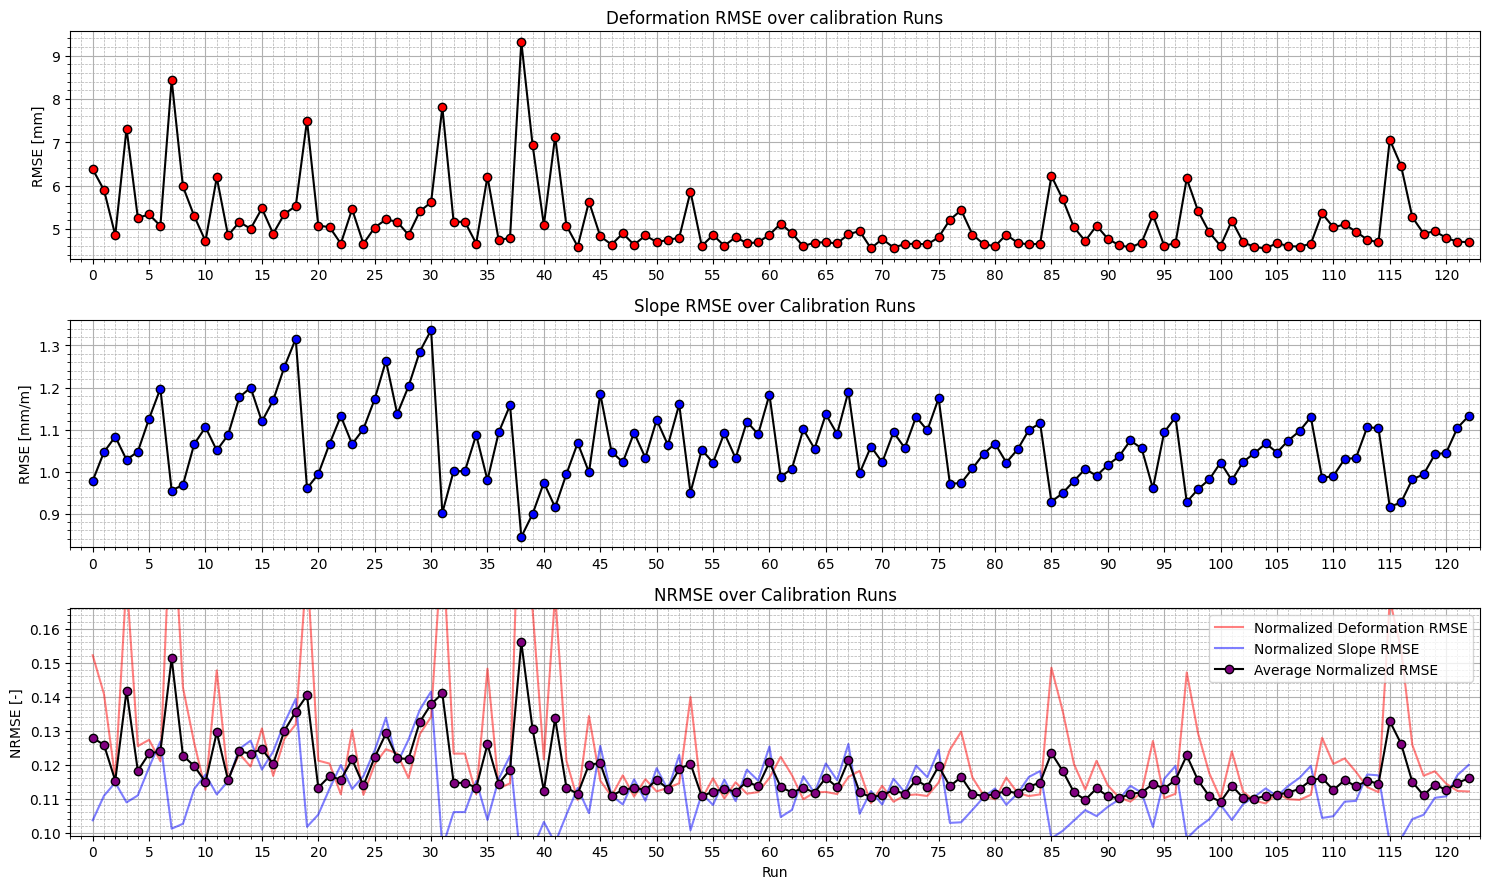

,Average_NRSME
100,0.109074
88,0.109643
103,0.109973
91,0.110051
102,0.1102


In [23]:
idx_min = plot_calibration_errors(RMSE_deform, RMSE_theta, NRSME_deform, NRSME_theta)

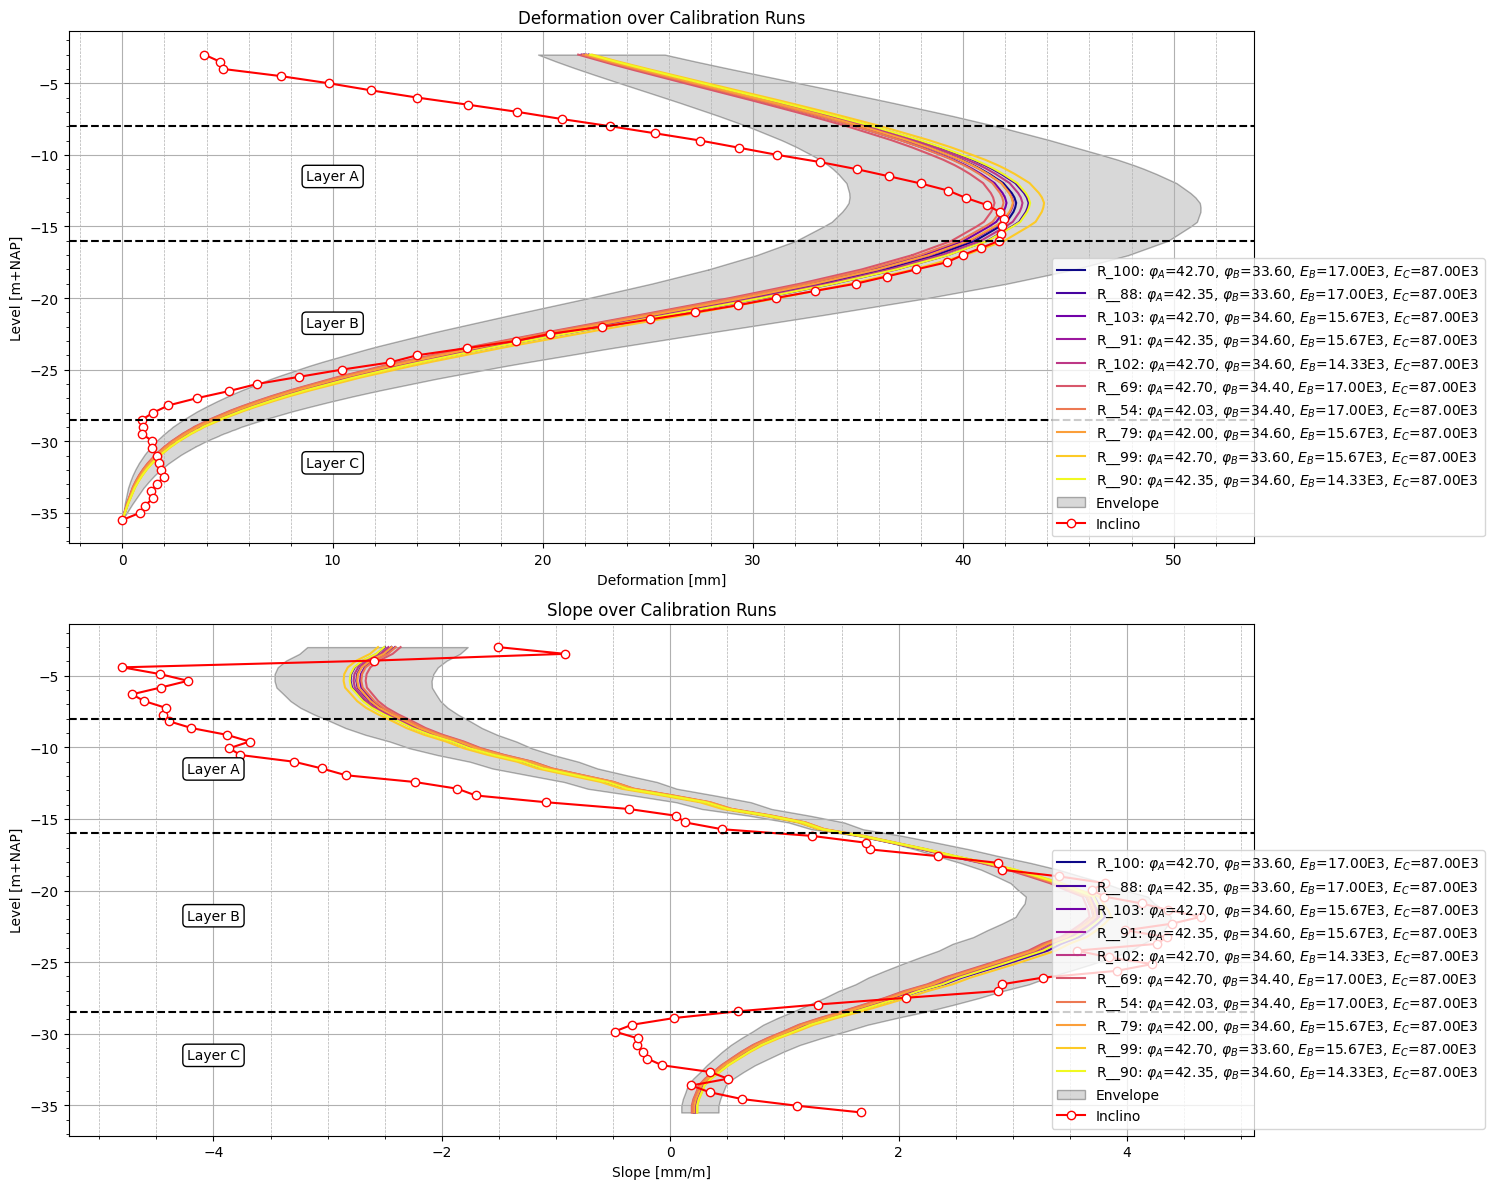

In [24]:
plot_best_runs(idx_min, log, U_cor, theta)